MSBD 566 – Predictive Modeling and Analytics


 Assignment 2: Validation, Tuning and Honest Evaluation

Keimora Wright

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "pd_speech_features.csv",
    header=1
)

print(df.shape)

df.head()

(756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [3]:
print("Shape:", df.shape)

print("\nMissing Values")
print(df.isnull().sum().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nUnique Subjects")
print(df["id"].nunique())

print("\nClass Counts")
print(df["class"].value_counts())

print("\nClass Percentages")
print(df["class"].value_counts(normalize=True))

subject_counts = df["id"].value_counts()

print("\nRecordings Per Subject")
print(subject_counts.describe())

Shape: (756, 755)

Missing Values
0

Duplicate Rows
1

Unique Subjects
252

Class Counts
class
1    564
0    192
Name: count, dtype: int64

Class Percentages
class
1    0.746032
0    0.253968
Name: proportion, dtype: float64

Recordings Per Subject
count    252.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
Name: count, dtype: float64


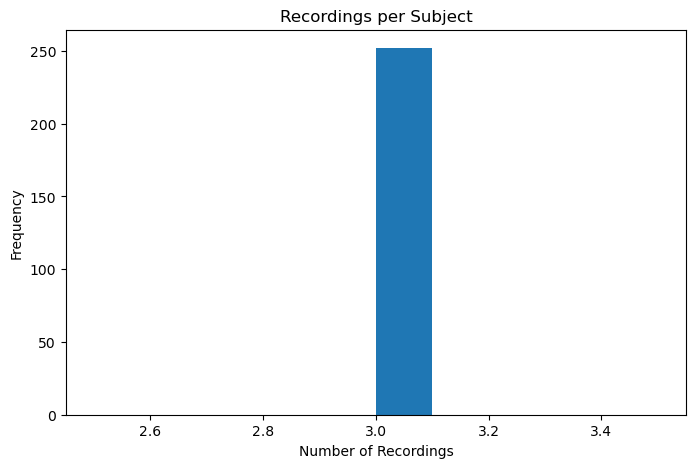

In [4]:
import matplotlib.pyplot as plt

subject_counts = df["id"].value_counts()

plt.figure(figsize=(8,5))

plt.hist(subject_counts)

plt.title("Recordings per Subject")

plt.xlabel("Number of Recordings")

plt.ylabel("Frequency")

plt.show()

In [5]:
majority_accuracy = (
    df["class"]
      .value_counts(normalize=True)
      .max()
)

print(
    f"Majority Baseline Accuracy = {majority_accuracy:.4f}"
)

Majority Baseline Accuracy = 0.7460


In [6]:
X = df.drop(
    columns=["id", "gender", "class"]
)

y = df["class"]

groups = df["id"]

In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

In [8]:
overlap = set(
    groups_train
).intersection(
    set(groups_test)
)

print(
    "Overlap Subjects:",
    len(overlap)
)

Overlap Subjects: 0
